Reza Namvaran 40212358042

In [85]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100

# Fixed colours for histogram series: original is always blue, processed always orange, and so on
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]


def load_gray(path):
    """Read an image as 8-bit grayscale; fail loudly if the path is wrong (cv2 returns None silently)."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    assert img is not None, f"{path} not found"
    return img


def show(ax, img, title, vmax=255, interpolation="antialiased"):
    """Display a grayscale image on a FIXED scale [0, vmax] so Matplotlib cannot auto-stretch it."""
    ax.imshow(img, cmap="gray", vmin=0, vmax=vmax, interpolation=interpolation)
    ax.set_title(title)
    ax.axis("off")


def plot_hist(ax, img, title, color=SERIES[0], normalised=False):
    """256-bin histogram for a uint8 image (0..255) or a normalised float image (0..1)."""
    if normalised:
        counts, edges = np.histogram(img, bins=256, range=(0, 1))
        ax.bar(edges[:-1], counts, width=1 / 256, align="edge", color=color)
        ax.set_xlim(0, 1)
        ax.set_xlabel("Intensity (0 to 1)")
        ax.set_ylabel("Frequency")
    else:
        counts = np.bincount(img.ravel(), minlength=256)
        ax.bar(np.arange(256), counts, width=1, color=color)
        ax.set_xlim(0, 255)
        ax.set_xlabel("Pixel intensity")
        ax.set_ylabel("Number of pixels")
    ax.set_title(title)

## Question 1 — Working with a Digital Image

### A) Read and display
Read camera.png in grayscale using cv2.imread and display it using Matplotlib.

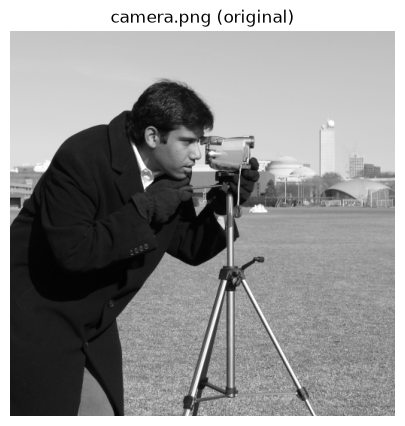

In [86]:
image = load_gray("camera.png")

fig, ax = plt.subplots(figsize=(5, 5))
show(ax, image, "camera.png (original)")
plt.show()

### B) Image properties

In [87]:
print("Shape:", image.shape)
print("Data type:", image.dtype)
print("Min value:", image.min())
print("Max value:", image.max())


Shape: (512, 512)
Data type: uint8
Min value: 0
Max value: 255


### shape
Shape is (rows, columns) or in other words (height, width).
From the result above we notice that shape is reported as (512, 512) which simply means the picture is 512 pixels in height and 512 pixels in width.

There are only two numbers because this is a 2D grayscale image, which does not have separate color channels.

### Data Type
uint8 stands for Unsigned 8-bit Integer. Each pixel can hold an integer value between 0 and 255. This is because 8 bits can represent 256 different values, starting from 0.

### Min Value
The minimum pixel value is 0, which represents pure black on the screen. Since the minimum is 0, the image contains at least one completely black pixel.

### Max Value
The maximum pixel value is 255, which represents pure white on the screen. Since the maximum is 255 and the minimum is 0, the image uses the full available intensity range (0–255), meaning it contains both pure black and pure white pixels.

### C) Pixel value and crop

image[100, 150] = 211
Crop shape: (30, 30)


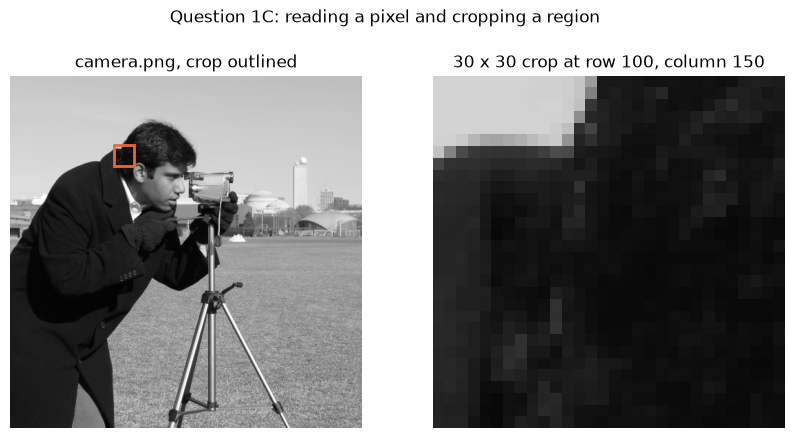

In [88]:
print("image[100, 150] =", image[100, 150])

crop30 = image[100:130, 150:180]
print("Crop shape:", crop30.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle("Question 1C: reading a pixel and cropping a region")
show(axes[0], image, "camera.png, crop outlined")
axes[0].add_patch(plt.Rectangle((150, 100), 30, 30, fill=False, edgecolor=SERIES[1], linewidth=2))
show(axes[1], crop30, "30 x 30 crop at row 100, column 150", interpolation="nearest")
plt.show()

### Pixel Intensity
The intensity value at image[100, 150] is 211.
- It is a bright pixel because its intensity (211) is much closer to 255 (white) than to 0 (black).
- It is reasonable for this pixel to be bright because it is located near the top of the Cameraman image, slightly left of the centre, where there are relatively bright areas.

### Cropping
The crop looks blocky because it contains only 30 × 30 pixels. When displayed at a larger size, each original pixel is enlarged into a visible square.

No additional image details are created during enlargement, so individual pixels become noticeable. This effect is called pixelation.

### D) 2D vs 3D arrays

In [89]:
color = cv2.imread("camera.png")
print("Grayscale shape:", image.shape, "-> image[100, 150] =", image[100, 150])
print("Colour shape:   ", color.shape, "-> color[100, 150] =", color[100, 150])

Grayscale shape: (512, 512) -> image[100, 150] = 211
Colour shape:    (512, 512, 3) -> color[100, 150] = [211 211 211]


A grayscale image is usually represented as a 2D array because each pixel contains only one value representing its brightness or intensity. These values form a grid with two dimensions: rows and columns. Therefore, its shape is `(height, width)`. For example, `image[row, col]` returns a single intensity value.

A colour image is commonly represented as a 3D array because each pixel contains three values representing its Red, Green, and Blue (RGB) components. This adds a third dimension for the colour channels, giving the shape `(height, width, 3)`. In this case, `image[row, col]` returns three values instead of one. (OpenCV commonly uses BGR instead of RGB.)

It is also important to distinguish between row/column indexing and x/y coordinates. In NumPy, images are accessed using `[row, column]`, where rows represent the vertical position (y) and columns represent the horizontal position (x). Therefore, `image[row, col]` is equivalent to `image[y, x]`, which is the reverse of the usual `(x, y)` coordinate order.

Understanding this difference is important because some OpenCV functions expect coordinates as `(x, y)` or dimensions as `(width, height)`. Mixing up these orders can cause incorrect pixel selection or image processing results.

## Question 2 — Basic Pixel-wise Operations
Perform arithmetic in a wider type, clip to [0, 255], and then convert to uint8. This avoids unsigned 8-bit overflow/wrap-around.

All three are **point operations**: each output pixel depends only on the input pixel in the same position. The rule for safe arithmetic is: **widen the type - compute - clip to [0, 255] - convert back to `uint8`**.

In [90]:
# A)
brighter = np.clip(image.astype(np.int16) + 40, 0, 255).astype(np.uint8)

# B) 
darker = np.round(image.astype(np.float64) * 0.5).astype(np.uint8)

# C)
negative = 255 - image

for name, img in [("Original", image), ("Brighter", brighter), ("Darker", darker), ("Negative", negative)]:
    print(f"{name:9s} min={img.min():3d}  max={img.max():3d}  mean={img.mean():6.1f}  pixels at 255: {np.sum(img == 255)}")

Original  min=  0  max=255  mean= 129.1  pixels at 255: 271
Brighter  min= 40  max=255  mean= 168.6  pixels at 255: 10393
Darker    min=  0  max=128  mean=  64.5  pixels at 255: 0
Negative  min=  0  max=255  mean= 125.9  pixels at 255: 1


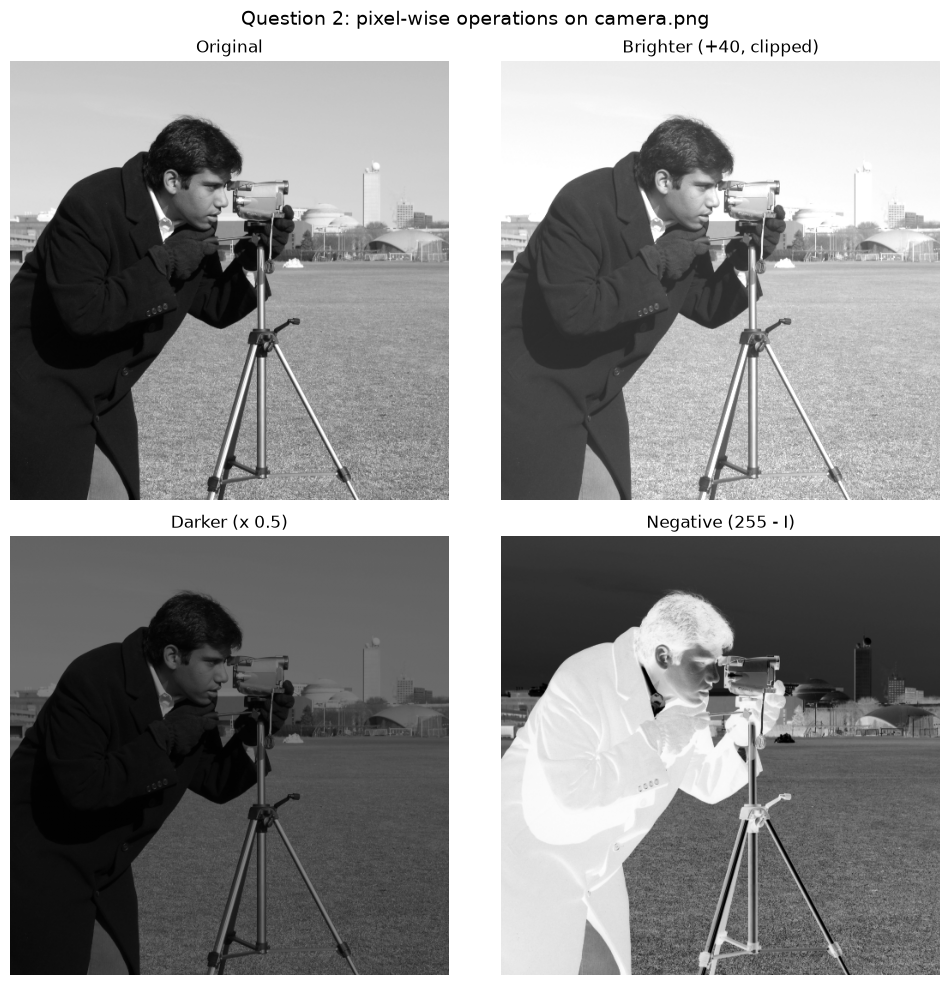

In [91]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
fig.suptitle("Question 2: pixel-wise operations on camera.png", fontsize=14)
show(axes[0, 0], image, "Original")
show(axes[0, 1], brighter, "Brighter (+40, clipped)")
show(axes[1, 0], darker, "Darker (x 0.5)")
show(axes[1, 1], negative, "Negative (255 - I)")
plt.tight_layout()
plt.show()

Adding 40 lifts every intensity, but the bright sky and the white shirt **saturate at 255** (the count of white pixels jumps, as printed above). Detail in those areas is lost permanently, because different values have been merged into one. Multiplying by 0.5 halves the range to 0–128, so the image is darker *and* has half the contrast; shadow detail in the coat becomes very hard to see. The negative reverses the grey scale (dark coat becomes light, bright sky becomes dark) without losing any information, because `255 − I` is a one-to-one mapping and applying it twice gives back the original.

### E) What happens to 230 + 40?

Raw uint8 addition:        [14]
Computed in int16:         [270]
Clipped and back to uint8: [255]


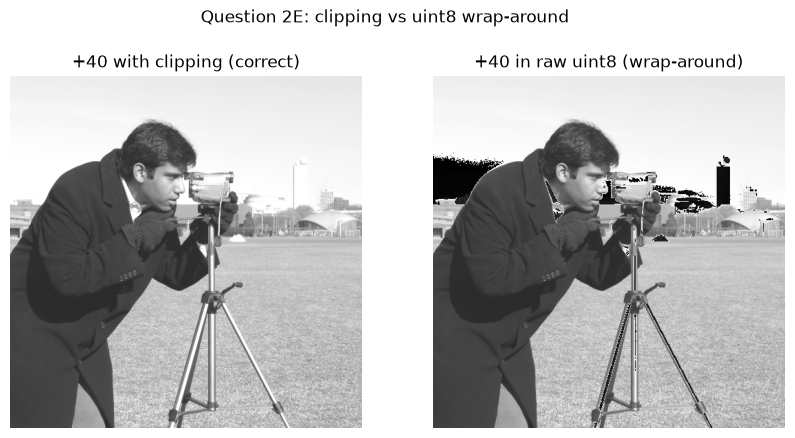

In [92]:
p = np.array([230], dtype=np.uint8)
print("Raw uint8 addition:       ", p + 40)                                  
print("Computed in int16:        ", p.astype(np.int16) + 40)
print("Clipped and back to uint8:", np.clip(p.astype(np.int16) + 40, 0, 255).astype(np.uint8))

wrapped = image + 40            
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle("Question 2E: clipping vs uint8 wrap-around")
show(axes[0], brighter, "+40 with clipping (correct)")
show(axes[1], wrapped, "+40 in raw uint8 (wrap-around)")
plt.show()

The value stored should be **255**. The true sum is 270, but `uint8` can only represent 0–255. Without clipping, `uint8` arithmetic works **modulo 256**, so 270 becomes 270 − 256 = **14**: a bright pixel turns almost black. That is what produces the black patches in the sky, on the white building and along the tripod in the right-hand image: exactly the pixels that were above 215. Clipping (also called **saturation**) is the correct behaviour: the pixel becomes as white as possible.

## Question 3: Histogram and Contrast Stretching

### A) Image and histogram

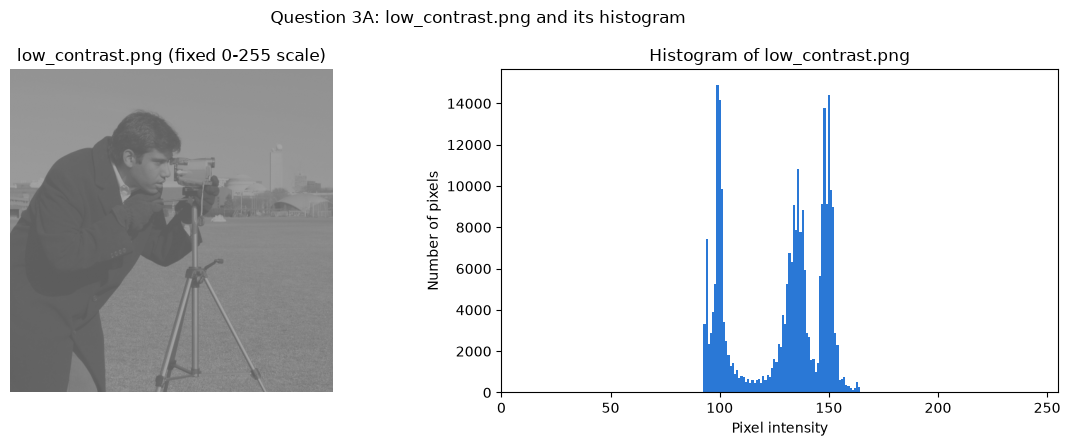

In [93]:
low = load_gray("low_contrast.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fig.suptitle("Question 3A: low_contrast.png and its histogram")
show(axes[0], low, "low_contrast.png (fixed 0-255 scale)")
plot_hist(axes[1], low, "Histogram of low_contrast.png")
plt.tight_layout()
plt.show()

### B) Minimum, maximum and interpretation

In [94]:
print("Minimum:", low.min(), " Maximum:", low.max(), " Range used:", int(low.max()) - int(low.min()), "of 255")
print("Distinct intensity levels:", len(np.unique(low)))

Minimum: 92  Maximum: 164  Range used: 72 of 255
Distinct intensity levels: 73


All values lie between **92 and 164**, about 28% of the available 0–255 range. The histogram has three peaks, all inside that band: around 95–105 (the dark coat), around 130–140 (the grass) and around 145–155 (the sky). Nothing is near black or white, so the darkest and brightest parts of the scene look like similar mid-greys: the image has **low contrast**. The histogram is narrow, not empty.

### C) Linear contrast stretching

In [95]:
def contrast_stretch(img):
    img_f = img.astype(np.float64)
    i_min, i_max = img_f.min(), img_f.max()
    if i_max == i_min:
        return img.copy()
    stretched = 255.0 * (img_f - i_min) / (i_max - i_min)
    return np.round(stretched).astype(np.uint8)


stretched = contrast_stretch(low)
print("Stretched range:", stretched.min(), "to", stretched.max())
print("Distinct levels before/after:", len(np.unique(low)), "/", len(np.unique(stretched)))

flat = np.full((4, 4), 120, dtype=np.uint8)            
print("Constant image handled:", np.array_equal(contrast_stretch(flat), flat))

Stretched range: 0 to 255
Distinct levels before/after: 73 / 73
Constant image handled: True


### D) Before and after

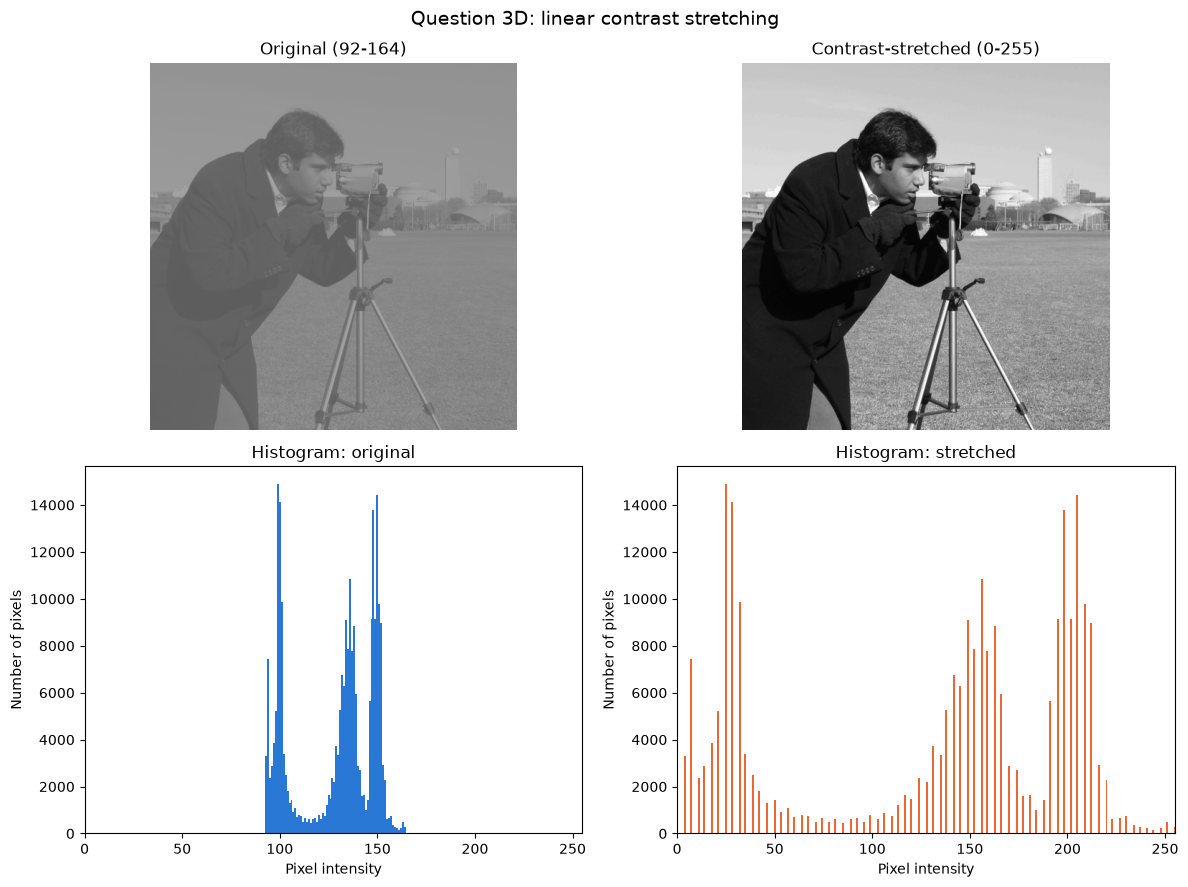

In [96]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.suptitle("Question 3D: linear contrast stretching", fontsize=14)
show(axes[0, 0], low, "Original (92-164)")
show(axes[0, 1], stretched, "Contrast-stretched (0-255)")
plot_hist(axes[1, 0], low, "Histogram: original", color=SERIES[0])
plot_hist(axes[1, 1], stretched, "Histogram: stretched", color=SERIES[1])
plt.tight_layout()
plt.show()

The stretched histogram covers the full 0–255 range, but it now has **gaps** (a comb shape). There were only 73 distinct levels before, and a linear map cannot create new ones; it only spaces the existing levels further apart.

### E) Can stretching recover hidden information?

**No.** Contrast stretching is a one-to-one rescaling of the values already present. It makes existing differences *easier to see*, but it cannot recreate detail that was never recorded, or that was destroyed by clipping or quantisation: two pixels that had the same value before still have the same value after, and the number of distinct levels does not increase (73 before and after). If all pixels have the same intensity, `I_max − I_min = 0` and the formula divides by zero. The program must check for this explicitly; the sensible output is to return the image unchanged (or a constant value), because a flat image has no contrast to stretch.

## Question 4: Image Zooming

The crop is taken from the camera body and hand, which have strong horizontal and diagonal edges.

Crop shape: (64, 64)


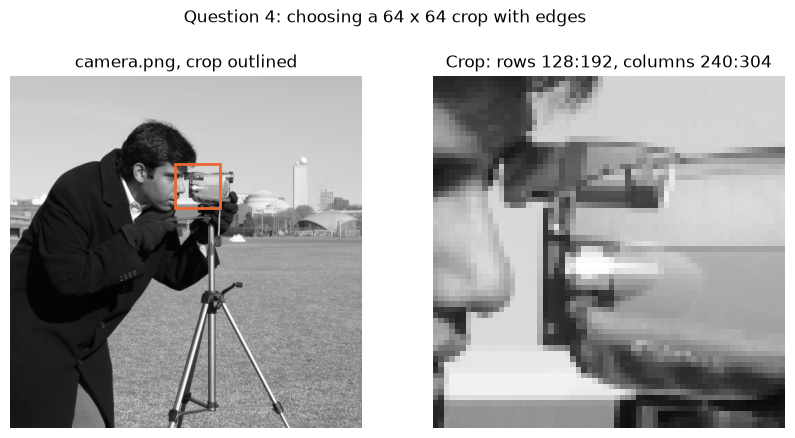

In [97]:
r0, c0 = 128, 240
crop = image[r0:r0 + 64, c0:c0 + 64]
print("Crop shape:", crop.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle("Question 4: choosing a 64 x 64 crop with edges")
show(axes[0], image, "camera.png, crop outlined")
axes[0].add_patch(plt.Rectangle((c0, r0), 64, 64, fill=False, edgecolor=SERIES[1], linewidth=2))
show(axes[1], crop, "Crop: rows 128:192, columns 240:304", interpolation="nearest")
plt.show()

### A) How nearest-neighbour zooming works

Zooming by a factor *k* creates an output grid *k* times larger in each direction. For each new pixel at `(r, c)`, nearest-neighbour finds the source pixel it falls on, `(r // k, c // k)`, and **copies that value unchanged**. No new intensity values are computed. The result is that each source pixel turns into a *k* × *k* block of identical pixels.

### B) 2× zoom with loops

In [98]:
def zoom_nearest_loops(img, factor):
    h, w = img.shape
    out = np.zeros((h * factor, w * factor), dtype=img.dtype)
    for r in range(h):
        for c in range(w):
            out[r * factor:(r + 1) * factor, c * factor:(c + 1) * factor] = img[r, c]
    return out


zoom2_loops = zoom_nearest_loops(crop, 2)
print("Input shape:", crop.shape, "-> output shape:", zoom2_loops.shape)
print("Top-left 2 x 2 source values:\n", crop[:2, :2])
print("Top-left 4 x 4 output values:\n", zoom2_loops[:4, :4])

Input shape: (64, 64) -> output shape: (128, 128)
Top-left 2 x 2 source values:
 [[38 41]
 [40 40]]
Top-left 4 x 4 output values:
 [[38 38 41 41]
 [38 38 41 41]
 [40 40 40 40]
 [40 40 40 40]]


### C) Comparison with `cv2.resize(..., INTER_NEAREST)`

Loop version shape:    (128, 128)
cv2.resize shape:      (128, 128)
Identical values:      True
Max absolute difference: 0


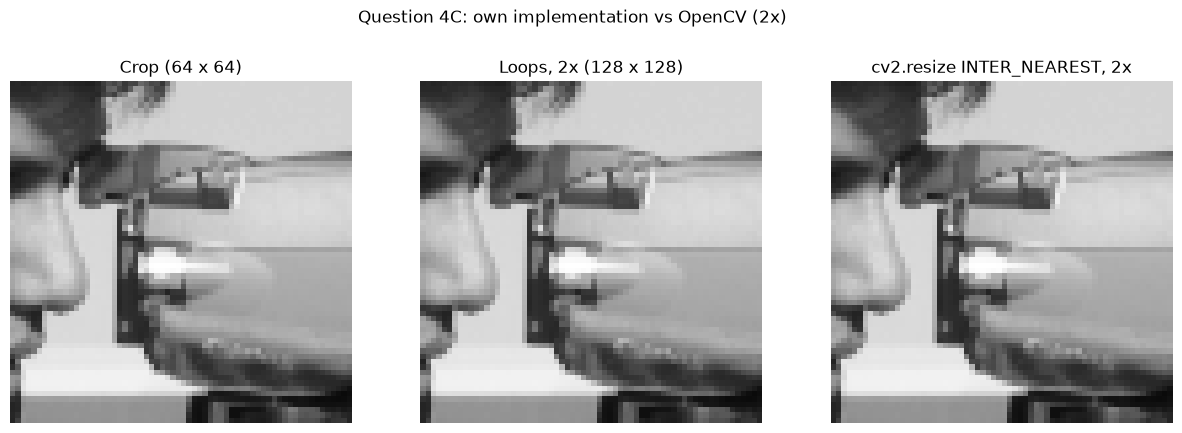

In [99]:
zoom2_cv = cv2.resize(crop, None, fx=2, fy=2, interpolation=cv2.INTER_NEAREST)

print("Loop version shape:   ", zoom2_loops.shape)
print("cv2.resize shape:     ", zoom2_cv.shape)
print("Identical values:     ", np.array_equal(zoom2_loops, zoom2_cv))
print("Max absolute difference:", np.abs(zoom2_loops.astype(int) - zoom2_cv.astype(int)).max())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Question 4C: own implementation vs OpenCV (2x)")
show(axes[0], crop, "Crop (64 x 64)", interpolation="nearest")
show(axes[1], zoom2_loops, "Loops, 2x (128 x 128)", interpolation="nearest")
show(axes[2], zoom2_cv, "cv2.resize INTER_NEAREST, 2x", interpolation="nearest")
plt.show()

Both outputs are **128 × 128** and every pixel value is identical (maximum difference 0). For an integer factor, OpenCV's nearest-neighbour maps output pixel `x` to source `floor(x / 2)`, which is exactly the block-copy done by the loops.

### D) 4× zoom

4x shape: (256, 256) | identical to OpenCV: True


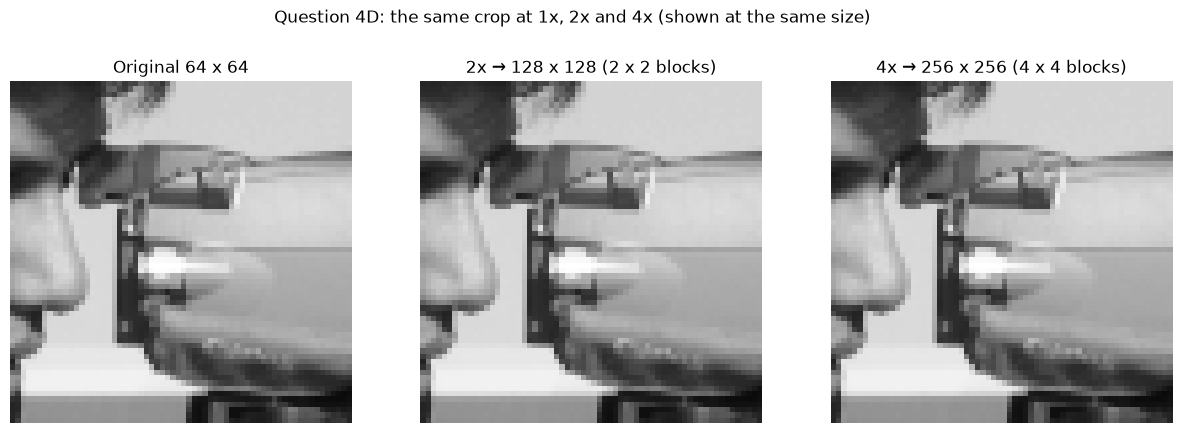

In [100]:
zoom4_loops = zoom_nearest_loops(crop, 4)
zoom4_cv = cv2.resize(crop, None, fx=4, fy=4, interpolation=cv2.INTER_NEAREST)
print("4x shape:", zoom4_loops.shape, "| identical to OpenCV:", np.array_equal(zoom4_loops, zoom4_cv))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Question 4D: the same crop at 1x, 2x and 4x (shown at the same size)")
show(axes[0], crop, "Original 64 x 64", interpolation="nearest")
show(axes[1], zoom2_loops, "2x → 128 x 128 (2 x 2 blocks)", interpolation="nearest")
show(axes[2], zoom4_loops, "4x → 256 x 256 (4 x 4 blocks)", interpolation="nearest")
plt.show()

Displayed at the same size, all three look the same: that is the point. Nearest-neighbour copies values, so **no new detail appears** at any factor. What changes is how the image looks when shown at its true pixel size: each source pixel becomes a larger, more visible square, diagonal edges turn into **staircases (jaggies)**, and fine texture becomes blocky. The higher the factor, the more obvious this pixelation becomes.


---
## Supplementary zooming task: Pixel Replication vs Zero-order Hold

### E) How each method assigns values

- **Pixel replication** is nearest-neighbour zooming: every pixel is copied *k* times along its row, then every row is copied *k* times. An n × n image becomes kn × kn, made of *k* × *k* constant blocks.
- **Zero-order hold** (as defined in the usual image-processing course notes) works on **pairs of neighbours**. It takes two adjacent pixels, computes their average, and inserts that value between them, first along every row and then along every column. For factor 2, an n × n image becomes (2n − 1) × (2n − 1). The textbook only defines factor 2; here it is generalised by inserting *k* − 1 copies of the average between each pair, giving `k(n − 1) + 1` pixels per side. The new pixel values are *averages*, so they did not exist in the original image.

### F) Implementations (no built-in resizing)

In [101]:
def pixel_replication(img, k):
    h, w = img.shape
    rows = np.arange(h * k) // k        
    cols = np.arange(w * k) // k        
    return img[rows[:, None], cols[None, :]]


def _zoh_along_rows(a, k):
    h, w = a.shape
    out = np.empty((h, k * (w - 1) + 1))
    out[:, ::k] = a                                 
    avg = (a[:, :-1] + a[:, 1:]) / 2                
    for j in range(1, k):
        out[:, j::k] = avg                          
    return out


def zero_order_hold(img, k):
    a = img.astype(np.float64)
    a = _zoh_along_rows(a, k)
    a = _zoh_along_rows(a.T, k).T
    return np.round(a).astype(np.uint8)


demo = np.array([[1, 2], [3, 4]], dtype=np.uint8)
print("Replication x2:\n", pixel_replication(demo, 2))
print("Zero-order hold x2 (before rounding):\n", _zoh_along_rows(_zoh_along_rows(demo.astype(float), 2).T, 2).T)

Replication x2:
 [[1 1 2 2]
 [1 1 2 2]
 [3 3 4 4]
 [3 3 4 4]]
Zero-order hold x2 (before rounding):
 [[1.  1.5 2. ]
 [2.  2.5 3. ]
 [3.  3.5 4. ]]


### G) Factor 3

Original               height= 360  width= 360
Pixel replication x3   height=1080  width=1080
Zero-order hold x3     height=1078  width=1078


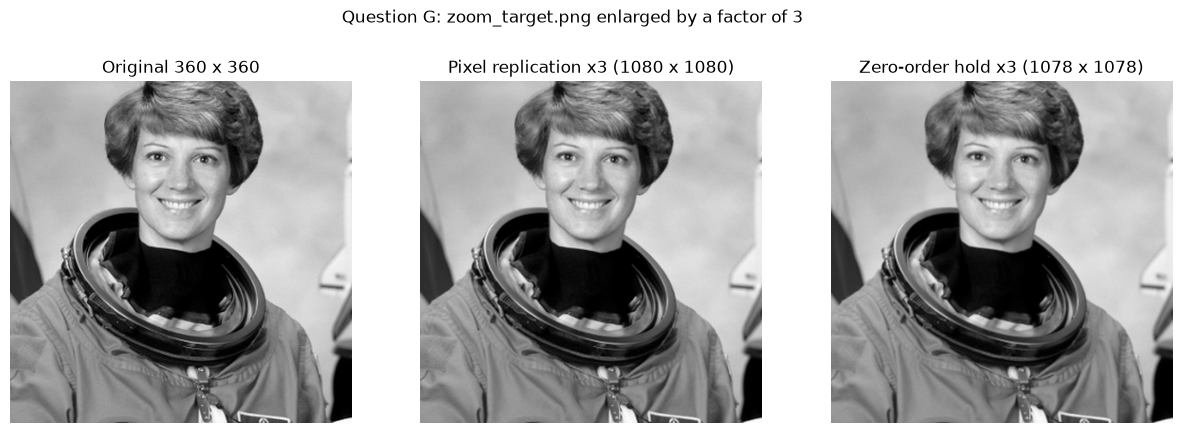

In [102]:
target = load_gray("zoom_target.png")
pr3 = pixel_replication(target, 3)
zoh3 = zero_order_hold(target, 3)

for name, img in [("Original", target), ("Pixel replication x3", pr3), ("Zero-order hold x3", zoh3)]:
    print(f"{name:22s} height={img.shape[0]:4d}  width={img.shape[1]:4d}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Question G: zoom_target.png enlarged by a factor of 3")
show(axes[0], target, f"Original {target.shape[1]} x {target.shape[0]}")
show(axes[1], pr3, f"Pixel replication x3 ({pr3.shape[1]} x {pr3.shape[0]})")
show(axes[2], zoh3, f"Zero-order hold x3 ({zoh3.shape[1]} x {zoh3.shape[0]})")
plt.show()

At full-image scale the two results look almost the same, because the differences are only a few pixels wide. Note the sizes: replication gives exactly 3 × 360 = 1080, while zero-order hold gives 3 × (360 − 1) + 1 = 1078, because new values are only inserted *between* pixels.

### H) Factor 5 and close-ups

Pixel replication x5   height=1800  width=1800
Zero-order hold x5     height=1796  width=1796


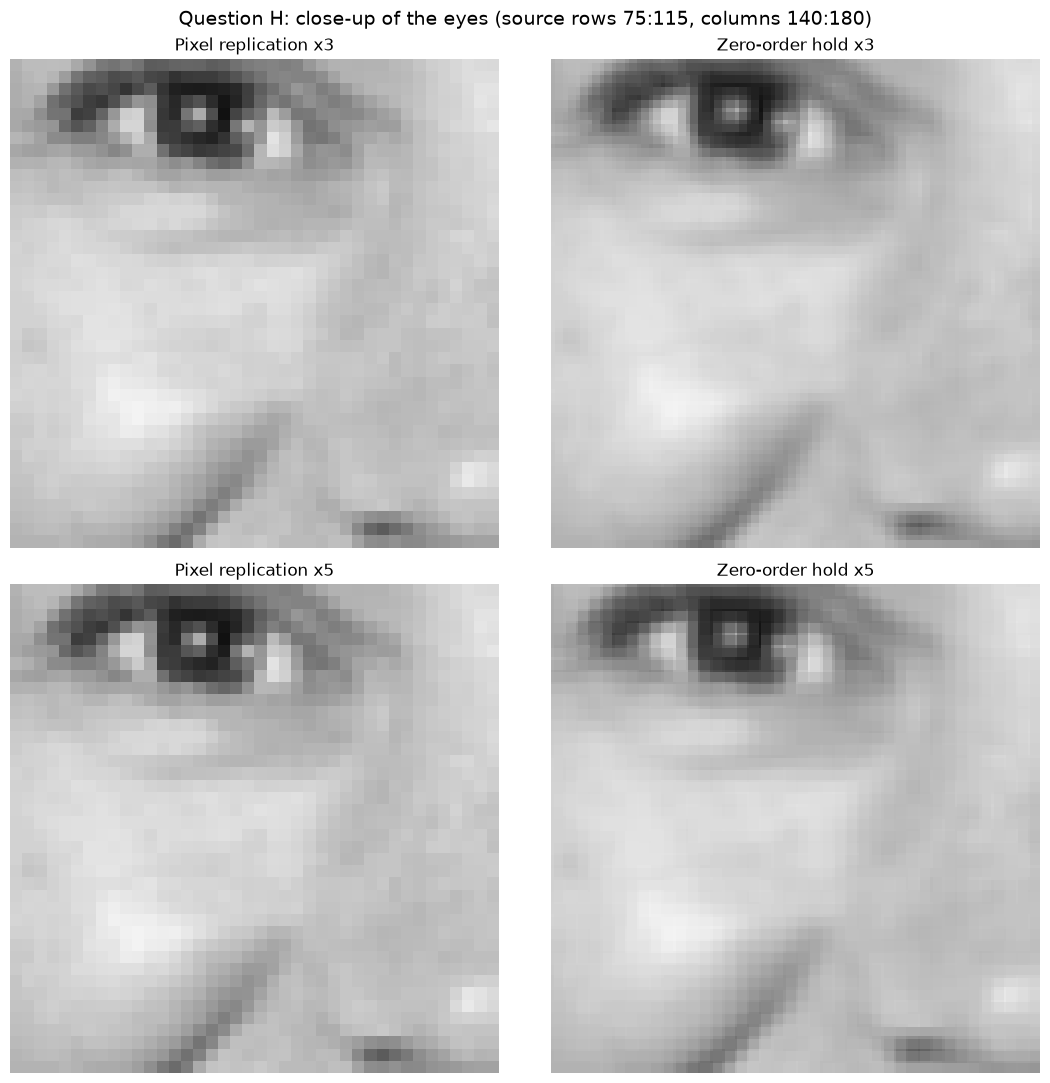

In [103]:
pr5 = pixel_replication(target, 5)
zoh5 = zero_order_hold(target, 5)
for name, img in [("Pixel replication x5", pr5), ("Zero-order hold x5", zoh5)]:
    print(f"{name:22s} height={img.shape[0]:4d}  width={img.shape[1]:4d}")

R0, R1, C0, C1 = 75, 115, 140, 180

def closeup(img, k):
    return img[R0 * k:R1 * k, C0 * k:C1 * k]

fig, axes = plt.subplots(2, 2, figsize=(11, 11))
fig.suptitle("Question H: close-up of the eyes (source rows 75:115, columns 140:180)", fontsize=14)
show(axes[0, 0], closeup(pr3, 3), "Pixel replication x3", interpolation="nearest")
show(axes[0, 1], closeup(zoh3, 3), "Zero-order hold x3", interpolation="nearest")
show(axes[1, 0], closeup(pr5, 5), "Pixel replication x5", interpolation="nearest")
show(axes[1, 1], closeup(zoh5, 5), "Zero-order hold x5", interpolation="nearest")
plt.tight_layout()
plt.show()

**Pixel replication** shows hard-edged square blocks, so edges such as the eyelids and iris form clear staircases. Shown at the same size, the ×3 and ×5 close-ups look **identical**: ×5 just uses 5 × 5 blocks instead of 3 × 3 to draw the same 40 × 40 source pixels. **Zero-order hold** gives softer transitions at ×3, because the inserted pixels are averages of their neighbours. At ×5 it looks *blockier* than at ×3: one averaged value is now held across 4 pixels instead of 2, so the image becomes a mosaic of small flat plateaus. Neither method recovers detail that is not in the 360 × 360 original (individual eyelashes stay blurred).

### I) Another method: bilinear interpolation

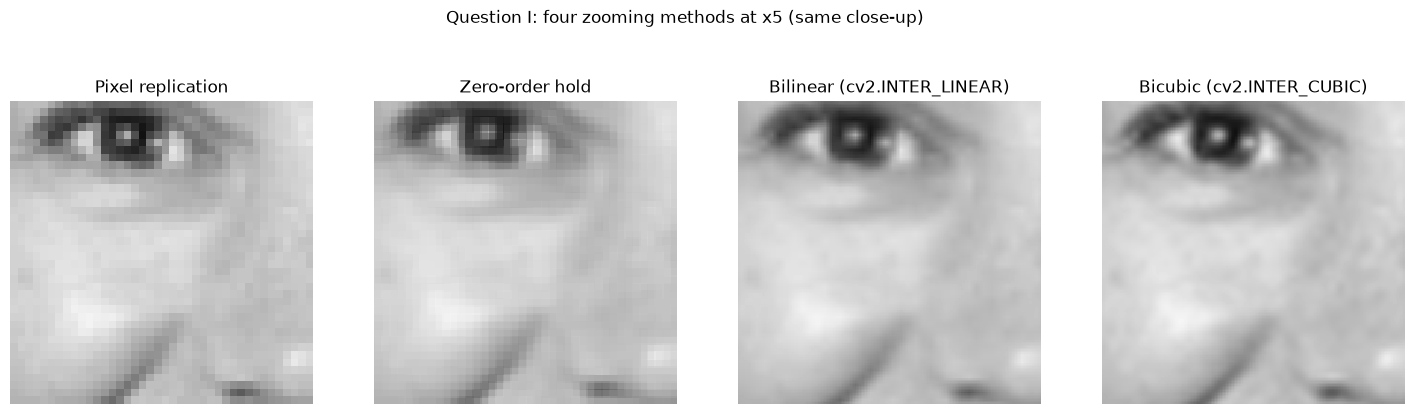

In [104]:
bilinear5 = cv2.resize(target, None, fx=5, fy=5, interpolation=cv2.INTER_LINEAR)
bicubic5 = cv2.resize(target, None, fx=5, fy=5, interpolation=cv2.INTER_CUBIC)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
fig.suptitle("Question I: four zooming methods at x5 (same close-up)")
show(axes[0], closeup(pr5, 5), "Pixel replication", interpolation="nearest")
show(axes[1], closeup(zoh5, 5), "Zero-order hold", interpolation="nearest")
show(axes[2], closeup(bilinear5, 5), "Bilinear (cv2.INTER_LINEAR)", interpolation="nearest")
show(axes[3], closeup(bicubic5, 5), "Bicubic (cv2.INTER_CUBIC)", interpolation="nearest")
plt.show()

**Bilinear interpolation** computes each new pixel as a distance-weighted average of the 4 nearest source pixels, so intensity changes *gradually* between samples instead of in steps. The block artefacts of replication and zero-order hold disappear, and diagonal edges look smooth, at the cost of slight overall blur (sharp edges are spread over several pixels). Bicubic uses 16 neighbours and gives slightly sharper edges than bilinear. Like the other methods, it still cannot invent real detail.

## Question 5: A Basic Geometric Translation

In [105]:
square = load_gray("square.png")
for v in (150, 220):
    rr, cc = np.nonzero(square == v)
    print(f"Intensity {v}: rows {rr.min()}..{rr.max()}, columns {cc.min()}..{cc.max()}, pixels = {rr.size}")

Intensity 150: rows 40..79, columns 40..79, pixels = 1600
Intensity 220: rows 130..209, columns 130..209, pixels = 6400


### A) Index changes

Moving 30 pixels **right** adds 30 to the **column** index (x); moving 20 pixels **down** adds 20 to the **row** index (y), because rows increase downwards. The square moves from rows 40:80 and columns 40:80 to **rows 60:100, columns 70:110**. Its size (40 × 40) is unchanged.

### B) Translate only the small square (array slicing, no `warpAffine`)

In [106]:
def translate_object(img, value, dy, dx, background=0):
    """Move only the pixels equal to `value` by dy rows and dx columns.

    Pixels pushed past the border are dropped; every other pixel stays where it is.
    """
    h, w = img.shape
    mask = img == value
    out = img.copy()
    out[mask] = background                          
    if abs(dy) >= h or abs(dx) >= w:
        return out                                  

    moved = np.zeros_like(mask)
    moved[max(dy, 0):h + min(dy, 0), max(dx, 0):w + min(dx, 0)] = \
        mask[max(-dy, 0):h - max(dy, 0), max(-dx, 0):w - max(dx, 0)]
    out[moved] = value                              
    return out


translated = translate_object(square, 150, dy=20, dx=30)
rr, cc = np.nonzero(translated == 150)
print(f"New position: rows {rr.min()}..{rr.max()}, columns {cc.min()}..{cc.max()}")

New position: rows 60..99, columns 70..109


### C) Display and check

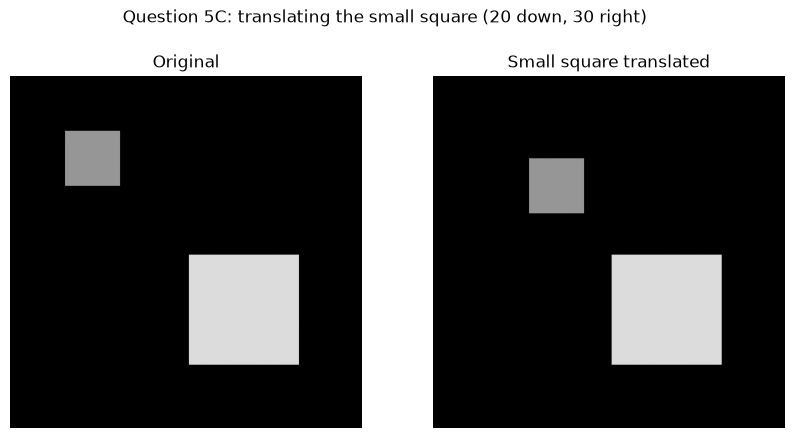

Pixels at 150 before: 1600 | after: 1600
Large square unchanged: True


In [107]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle("Question 5C: translating the small square (20 down, 30 right)")
show(axes[0], square, "Original")
show(axes[1], translated, "Small square translated")
plt.show()

print("Pixels at 150 before:", np.sum(square == 150), "| after:", np.sum(translated == 150))
print("Large square unchanged:", np.array_equal(square == 220, translated == 220))

The count of intensity-150 pixels is **1600 before and after** (40 × 40), and the large square's pixels are identical, so only the small square moved and nothing was lost or changed.

### D) Moving past the border

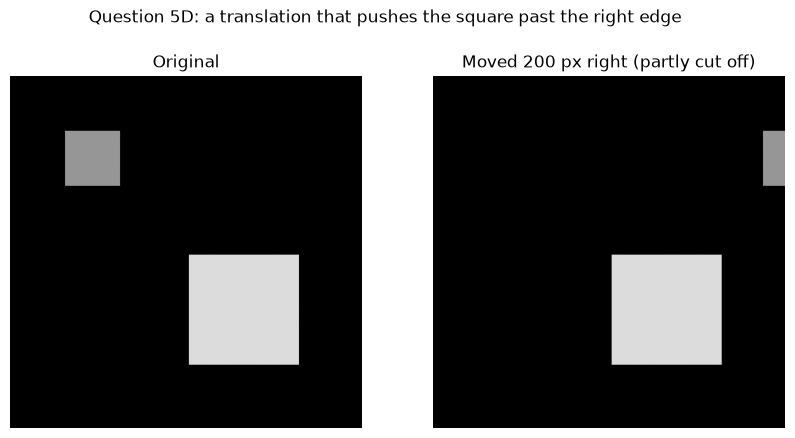

Pixels at 150 before: 1600 | after: 640


In [108]:
off_edge = translate_object(square, 150, dy=0, dx=200)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle("Question 5D: a translation that pushes the square past the right edge")
show(axes[0], square, "Original")
show(axes[1], off_edge, "Moved 200 px right (partly cut off)")
plt.show()
print("Pixels at 150 before:", np.sum(square == 150), "| after:", np.sum(off_edge == 150))

The output image has a fixed size (256 × 256). A translated pixel whose new column or row is outside 0..255 has nowhere to be stored, so it is discarded. Here the square should occupy columns 240:280, but only 240:256 exist, so just 16 × 40 = 640 of its 1600 pixels survive. The rest of the object is lost (unless the canvas is enlarged or the image wraps around, as `np.roll` would do, which is usually not wanted).


## Question 6: Logarithmic and Gamma Correction

### A) Normalise to [0, 1]

In [109]:
scene = load_gray("low_contrast_scene.png")
f = scene.astype(np.float64) / 255.0
print("Shape:", f.shape, f"| range {f.min():.3f} to {f.max():.3f} | mean {f.mean():.3f}")

Shape: (300, 420) | range 0.263 to 0.486 | mean 0.400


Dividing by 255 maps 0 → 0 and 255 → 1 while keeping the *absolute* brightness (this image uses only about 0.26–0.49). Min-max normalisation would instead be a contrast stretch.

### B) Purpose

- **Logarithmic correction** `c·log(1 + f)` expands **dark** values and compresses bright ones (steep slope near 0, flat near 1). It is used for images with a huge dynamic range (Fourier spectra, HDR, scenes with deep shadows) so that dark detail becomes visible.
- **Gamma correction** `f^γ` is a family of power curves controlled by one parameter: **γ < 1 brightens** (lifts mid-tones and dark tones), **γ > 1 darkens**. It corrects the non-linear response of displays and cameras, and adjusts mid-tone brightness without moving black (0) or white (1).

### C) Logarithmic transform

In [110]:
c_log = 1 / np.log(2)                  
log_img = c_log * np.log(1 + f)
print(f"c = {c_log:.4f} | output range {log_img.min():.3f} to {log_img.max():.3f}")

c = 1.4427 | output range 0.337 to 0.572


**Choice of c:** since the largest possible input is 1, choosing `c = 1 / log(2)` makes the curve pass through (0, 0) and (1, 1), so *any* normalised image stays within [0, 1]. (An alternative, `c = 1 / log(1 + f.max())`, forces this image's brightest pixel to exactly 1. That combines the log with a stretch.)

### D) Gamma correction

In [111]:
gamma05 = np.power(f, 0.5)     
gamma15 = np.power(f, 1.5)

results6 = [("Original", f), ("Log", log_img), ("Gamma 0.5", gamma05), ("Gamma 1.5", gamma15)]
for name, img in results6:
    print(f"{name:10s} range {img.min():.3f} to {img.max():.3f}  (spread {img.max() - img.min():.3f})  mean {img.mean():.3f}")

Original   range 0.263 to 0.486  (spread 0.224)  mean 0.400
Log        range 0.337 to 0.572  (spread 0.235)  mean 0.485
Gamma 0.5  range 0.513 to 0.697  (spread 0.185)  mean 0.632
Gamma 1.5  range 0.135 to 0.339  (spread 0.204)  mean 0.254


### E) Images and histograms

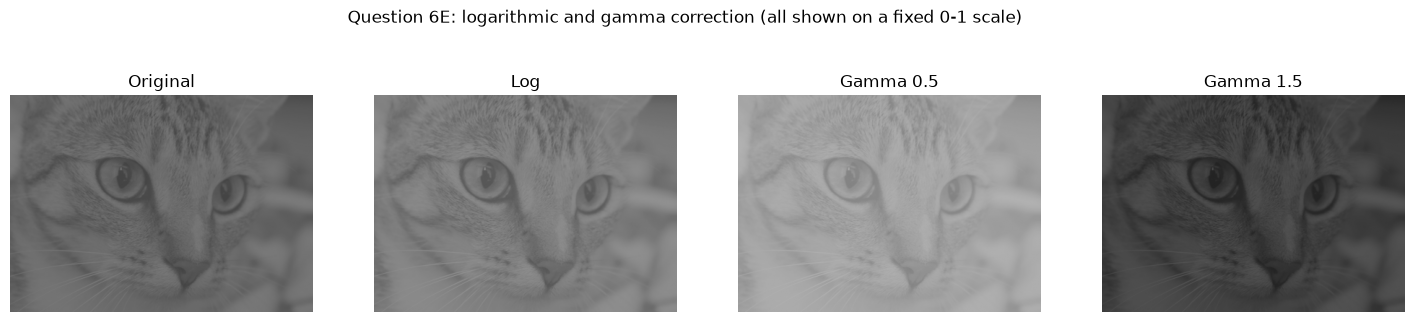

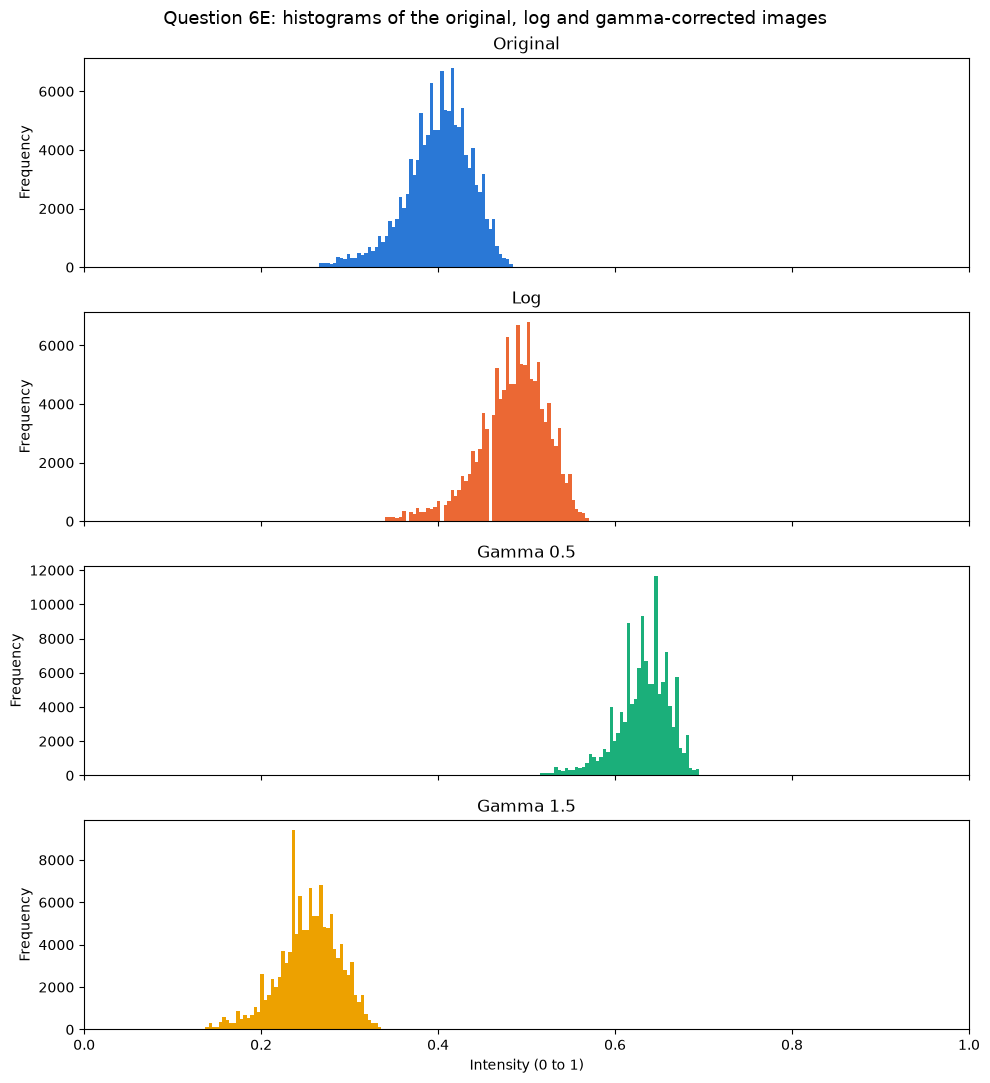

In [112]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
fig.suptitle("Question 6E: logarithmic and gamma correction (all shown on a fixed 0-1 scale)")
for ax, (name, img) in zip(axes, results6):
    show(ax, img, name, vmax=1)
plt.show()

fig, axes = plt.subplots(4, 1, figsize=(10, 11), sharex=True)
fig.suptitle("Question 6E: histograms of the original, log and gamma-corrected images", fontsize=13)
for ax, (name, img), color in zip(axes, results6, SERIES):
    plot_hist(ax, img, name, color=color, normalised=True)
    ax.set_xlabel("")
axes[-1].set_xlabel("Intensity (0 to 1)")
plt.tight_layout()
plt.show()

The **log** and **γ = 0.5** curves move the whole histogram to the right (brighter); **γ = 1.5** moves it left (darker). Look at the *spread* printed above, though: it barely changes. These are fixed global curves, and over a narrow input band (0.26–0.49) any smooth curve is almost a straight line, so they mainly shift brightness and do little for contrast. The histograms also keep the same 58 spikes with gaps between them, because a point transform cannot create new levels. To increase contrast in an image like this, use contrast stretching (Q3) or equalisation (Q7).


## Question 7: Histogram Equalisation

### A) Normalise

In [113]:
eq_src = load_gray("equalization_scene.png")
g = eq_src.astype(np.float64) / 255.0
print("Shape:", g.shape, f"| range {g.min():.3f} to {g.max():.3f} | mean {g.mean():.3f}")

Shape: (420, 420) | range 0.000 to 1.000 | mean 0.506


### B) Histogram of the original

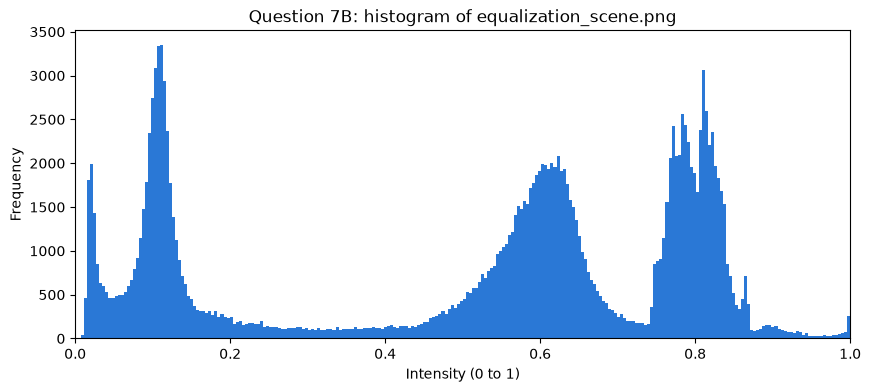

In [114]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_hist(ax, g, "Question 7B: histogram of equalization_scene.png", normalised=True)
plt.show()

The image uses the full range, but unevenly. There are three main peaks: a dark one around 0.1 (the coat), one around 0.6 (the grass) and a bright one around 0.8 (the sky). There are relatively few pixels between 0.2 and 0.5, so much of the available range is wasted on tones the image hardly uses.

### C) Equalisation using the cumulative histogram

The equalisation mapping is the **cumulative distribution function (CDF)** of the intensities: `s_k = T(r_k) = Σ_{j ≤ k} n_j / N`. A level below which 30% of pixels lie is sent to 0.3, and so on, so the output levels are as evenly used as possible.

Equalised range 0.000 to 1.000 | mean 0.504
vs cv2.equalizeHist: mean |difference| = 0.00 levels, max = 0


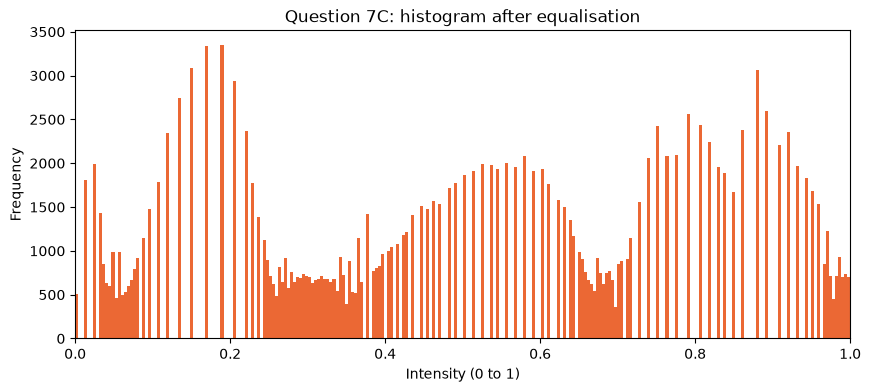

In [115]:
def equalize(f, levels=256):
    k = np.round(f * (levels - 1)).astype(int)       
    hist = np.bincount(k.ravel(), minlength=levels)     
    cdf = np.cumsum(hist) / k.size     
    return cdf[k]           


g_eq = equalize(g)
print(f"Equalised range {g_eq.min():.3f} to {g_eq.max():.3f} | mean {g_eq.mean():.3f}")

ours_u8 = np.round(g_eq * 255).astype(np.uint8)
diff = np.abs(ours_u8.astype(int) - cv2.equalizeHist(eq_src).astype(int))
print(f"vs cv2.equalizeHist: mean |difference| = {diff.mean():.2f} levels, max = {diff.max()}")

fig, ax = plt.subplots(figsize=(10, 4))
plot_hist(ax, g_eq, "Question 7C: histogram after equalisation", color=SERIES[1], normalised=True)
plt.show()

### D) Everything together

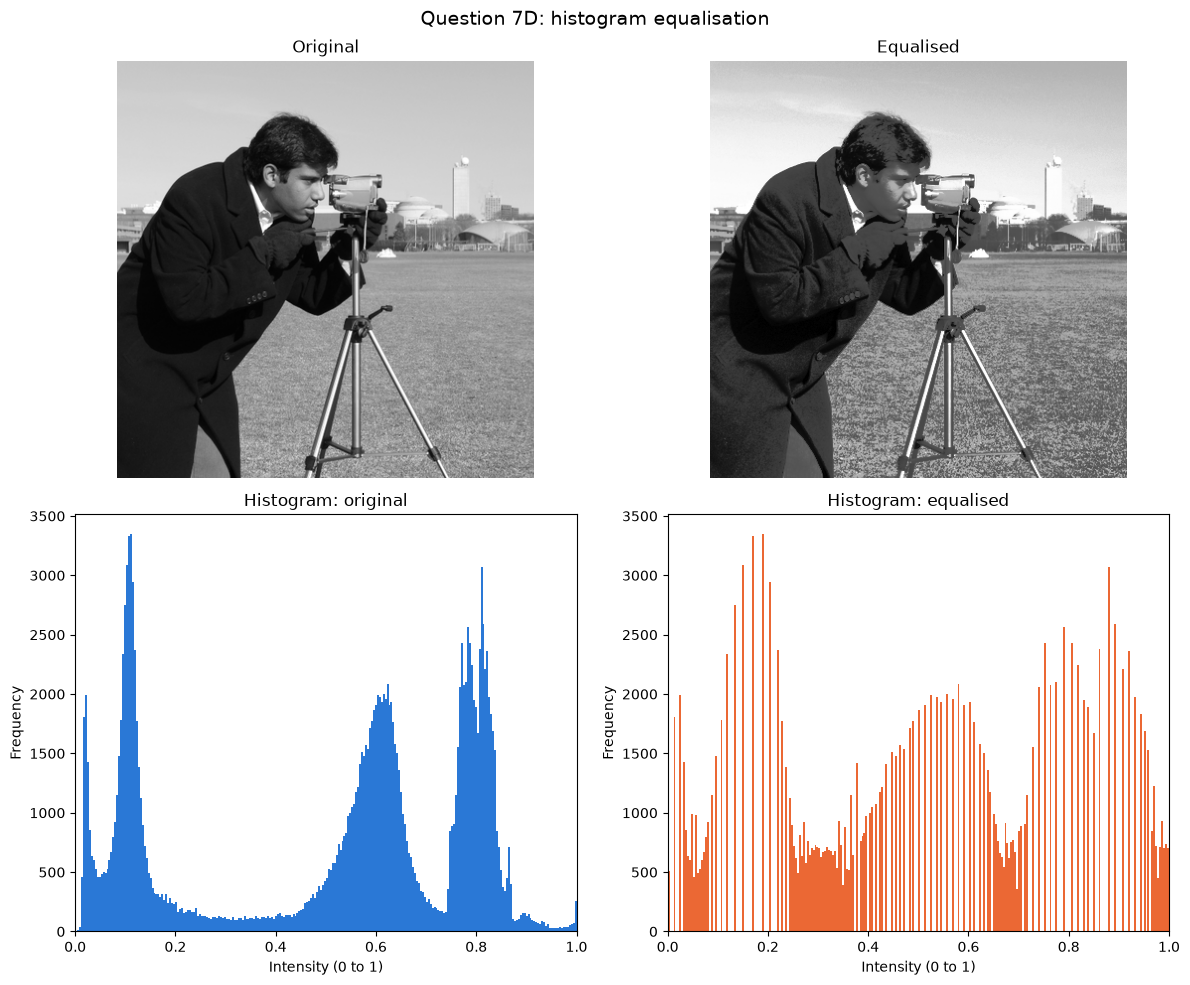

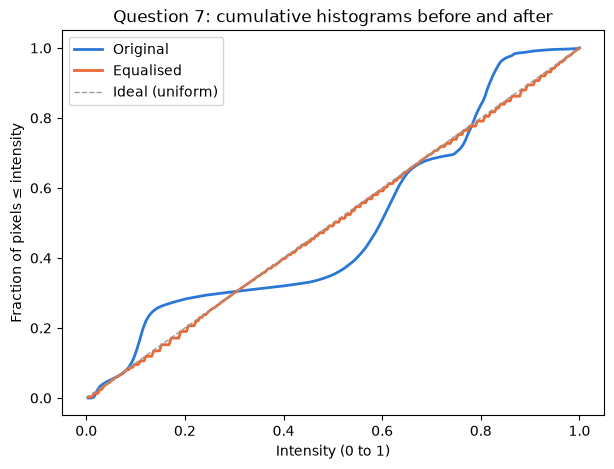

In [116]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle("Question 7D: histogram equalisation", fontsize=14)
show(axes[0, 0], g, "Original", vmax=1)
show(axes[0, 1], g_eq, "Equalised", vmax=1)
plot_hist(axes[1, 0], g, "Histogram: original", color=SERIES[0], normalised=True)
plot_hist(axes[1, 1], g_eq, "Histogram: equalised", color=SERIES[1], normalised=True)
axes[1, 1].set_ylim(axes[1, 0].get_ylim())       
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for img, name, color in [(g, "Original", SERIES[0]), (g_eq, "Equalised", SERIES[1])]:
    counts, edges = np.histogram(img, bins=256, range=(0, 1))
    ax.plot(edges[1:], np.cumsum(counts) / img.size, color=color, linewidth=2, label=name)
ax.plot([0, 1], [0, 1], color="0.6", linestyle="--", linewidth=1, label="Ideal (uniform)")
ax.set_title("Question 7: cumulative histograms before and after")
ax.set_xlabel("Intensity (0 to 1)")
ax.set_ylabel("Fraction of pixels ≤ intensity")
ax.legend()
plt.show()

### E) Comparison

Equalisation **spreads the intensities across the whole [0, 1] range**: the two crowded peaks are pulled apart and moved towards the ends, and the mid-tones, which were rarely used before, are now well populated. Visually, the image gets more global contrast. Detail inside the dark coat becomes visible, and the grass texture is stronger, but noise and texture in large uniform areas (the sky) are also amplified, and the image can look harsher or less natural. The histogram is not perfectly flat. Pixels sharing one input level must stay together, so the output has tall isolated bars with gaps between them. The **cumulative** histogram, however, is close to the ideal straight line, which is exactly what equalisation aims for.


## Question 8: Geometric Transformations: Translation and Rotation

In [117]:
shapes = load_gray("geometric_shapes.png")
for v, name in [(135, "circle"), (220, "triangle")]:
    rr, cc = np.nonzero(shapes == v)
    print(f"{name:8s} (value {v}): rows {rr.min()}..{rr.max()}, columns {cc.min()}..{cc.max()}, "
          f"centroid (row, col) = ({rr.mean():.1f}, {cc.mean():.1f}), pixels = {rr.size}")

circle   (value 135): rows 146..194, columns 54..102, centroid (row, col) = (170.0, 78.0), pixels = 1877
triangle (value 220): rows 45..145, columns 152..258, centroid (row, col) = (111.7, 205.0), pixels = 5453


### A) and B) Approach

- **Translation** of the circle: 35 px right → column + 35; 25 px down → row + 25. The same `translate_object` function from Q5 is reused.
- **Rotation** of the triangle by 45° counter-clockwise **about its own centroid** (rotating about the image origin (0, 0) would swing it off the image). This uses **inverse mapping**: for every *output* pixel, rotate its coordinates *back* by −45° to find where it came from in the input, and copy that pixel (nearest neighbour). Forward mapping (pushing each input pixel to its new position) would leave holes, because rounded rotated positions do not cover every output pixel.

Because the y axis points *down* in images, a counter-clockwise rotation *as seen on screen* has the opposite sin signs from the textbook maths formula.

### C) Code and result

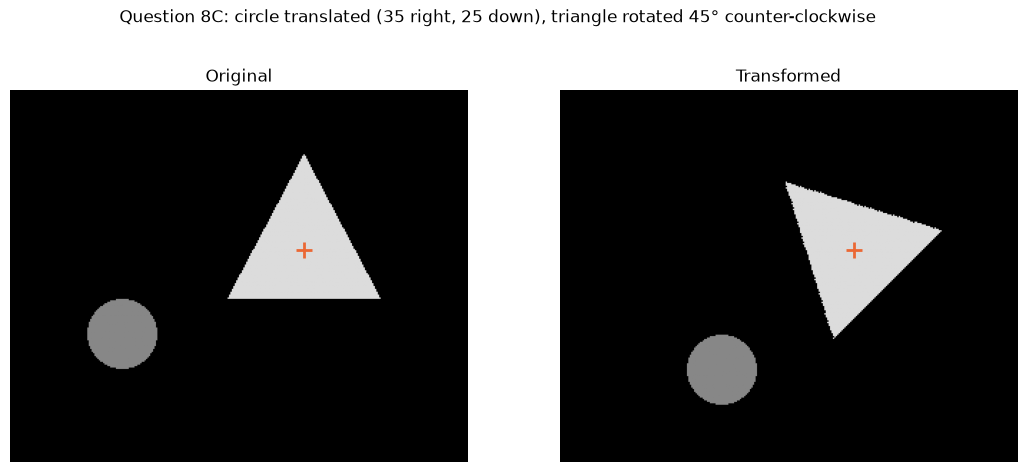

In [118]:
def rotate_object(img, value, angle_deg, background=0):
    h, w = img.shape
    mask = img == value
    cy, cx = np.argwhere(mask).mean(axis=0)       
    t = np.deg2rad(angle_deg)

    ys, xs = np.mgrid[0:h, 0:w]                         
    dx, dy = xs - cx, ys - cy
    src_x = np.rint(cx + dx * np.cos(t) - dy * np.sin(t)).astype(int)
    src_y = np.rint(cy + dx * np.sin(t) + dy * np.cos(t)).astype(int)

    inside = (src_x >= 0) & (src_x < w) & (src_y >= 0) & (src_y < h)
    rotated = np.zeros_like(mask)
    rotated[inside] = mask[src_y[inside], src_x[inside]]

    out = img.copy()
    out[mask] = background                           
    out[rotated] = value      
    return out, (cx, cy)


step1 = translate_object(shapes, 135, dy=25, dx=35)   
result8, (cx, cy) = rotate_object(step1, 220, 45)        

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle("Question 8C: circle translated (35 right, 25 down), triangle rotated 45° counter-clockwise")
show(axes[0], shapes, "Original")
show(axes[1], result8, "Transformed")
for ax in axes:
    ax.plot(cx, cy, "+", color=SERIES[1], markersize=12, markeredgewidth=2)   
plt.show()

In [119]:
print("Circle pixels before/after:  ", np.sum(shapes == 135), "/", np.sum(result8 == 135))
print("Triangle pixels before/after:", np.sum(shapes == 220), "/", np.sum(result8 == 220),
      "(small differences come from rounding to the pixel grid)")

M = cv2.getRotationMatrix2D((cx, cy), 45, 1.0)                     
cv_tri = cv2.warpAffine((shapes == 220).astype(np.uint8), M, (shapes.shape[1], shapes.shape[0]),
                        flags=cv2.INTER_NEAREST) > 0           
ours_tri = result8 == 220
agree = np.sum(ours_tri & cv_tri) / np.sum(ours_tri | cv_tri)
print(f"Overlap with cv2.warpAffine result (IoU): {agree:.4f}")

Circle pixels before/after:   1877 / 1877
Triangle pixels before/after: 5453 / 5452 (small differences come from rounding to the pixel grid)
Overlap with cv2.warpAffine result (IoU): 1.0000


The circle keeps exactly the same number of pixels (pure translation by whole pixels). The triangle's pixel count changes slightly, because the rotated edges are re-sampled onto the pixel grid. The result matches OpenCV's `warpAffine` exactly (IoU = 1.0), which confirms the direction (counter-clockwise) and the centre.

## Question 9: Additional Intensity Transformations

In [120]:
moon = load_gray("intensity_transform_scene.png")
h9 = moon.astype(np.float64) / 255.0
print(f"Range {h9.min():.3f} to {h9.max():.3f} | 5th-95th percentile {np.percentile(h9, 5):.3f}-{np.percentile(h9, 95):.3f}")

Range 0.000 to 1.000 | 5th-95th percentile 0.380-0.482


Almost all pixels lie in a narrow mid-grey band (about 0.38–0.48), with a few very dark (crater shadows) and very bright (sunlit rims) pixels.

### A) The three transformations

In [121]:
c_exp = 2.0
exp_img = (np.exp(c_exp * h9) - 1) / (np.exp(c_exp) - 1)

c_log10 = 1 / np.log10(2)
log10_img = c_log10 * np.log10(h9 + 1)

piece_raw = np.where(h9 < 0.1, h9, 2 * h9)
piece_img = np.clip(piece_raw, 0, 1)

results9 = [("Original", h9), ("Exponential (c = 2, rescaled)", exp_img),
            ("Log10 (c = 1/log10 2)", log10_img), ("Piecewise (x2 above 0.1, clipped)", piece_img)]
for name, img in results9:
    p5, p95 = np.percentile(img, [5, 95])
    print(f"{name:34s} 5th-95th percentile {p5:.3f}-{p95:.3f}  (middle-90% spread {p95 - p5:.3f})")
print(f"\nPiecewise: {np.mean(piece_raw > 1) * 100:.2f}% of pixels clipped at 1, "
      f"{np.mean(h9 < 0.1) * 100:.2f}% left unchanged (< 0.1)")

Original                           5th-95th percentile 0.380-0.482  (middle-90% spread 0.102)
Exponential (c = 2, rescaled)      5th-95th percentile 0.178-0.254  (middle-90% spread 0.076)
Log10 (c = 1/log10 2)              5th-95th percentile 0.465-0.568  (middle-90% spread 0.103)
Piecewise (x2 above 0.1, clipped)  5th-95th percentile 0.761-0.965  (middle-90% spread 0.204)

Piecewise: 2.31% of pixels clipped at 1, 0.42% left unchanged (< 0.1)


**What was done:** for the exponential, `c = 2` was chosen and the result rescaled with `(e^{2f} − 1) / (e² − 1)`, so the output lies exactly in [0, 1]. For the base-10 log, `c = 1 / log10(2)` so that the maximum input of 1 maps to 1. For the piecewise transform, values doubled above 1 are clipped to 1.

### B) All results together

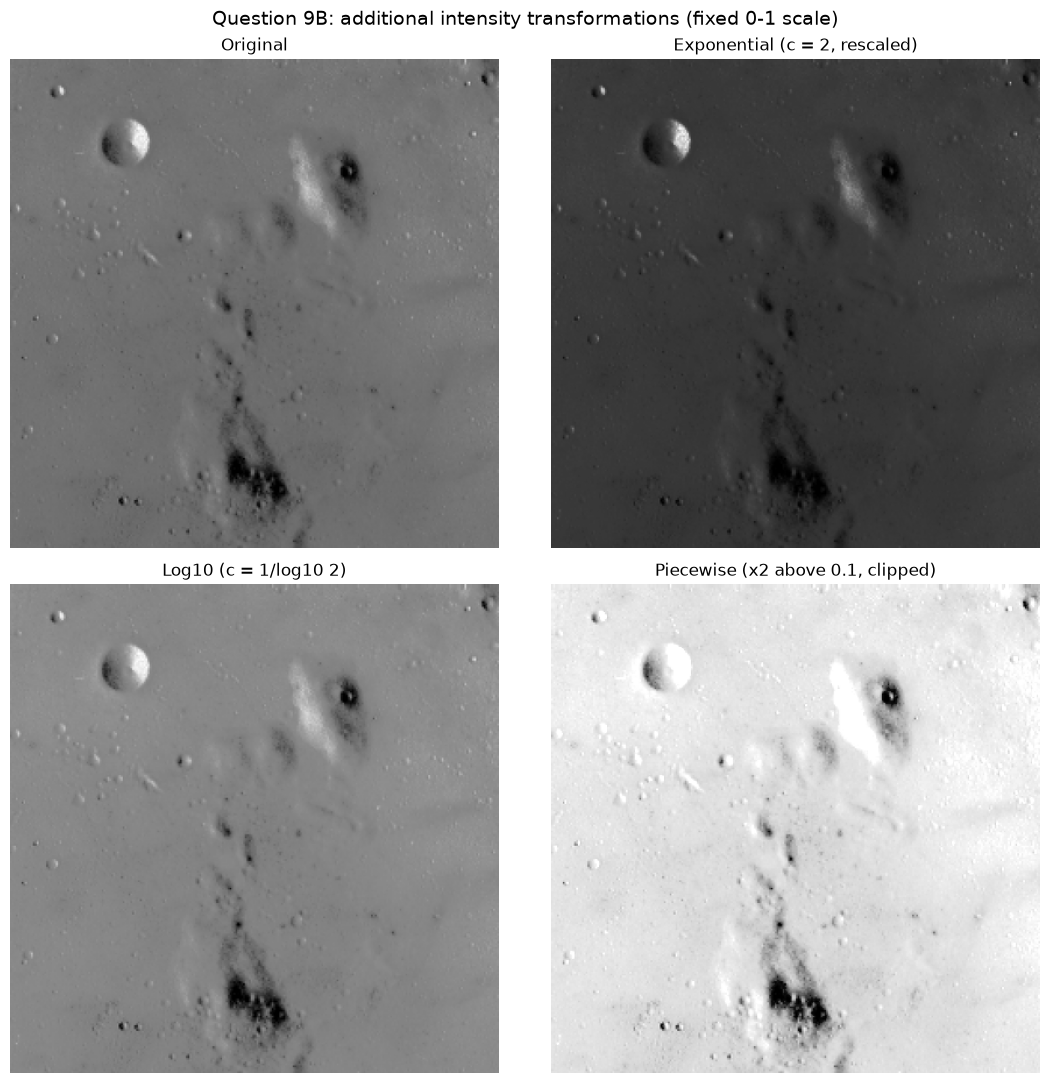

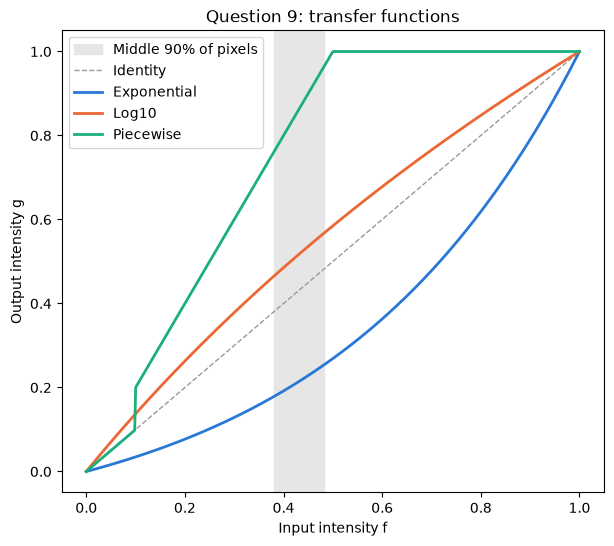

In [122]:
fig, axes = plt.subplots(2, 2, figsize=(11, 11))
fig.suptitle("Question 9B: additional intensity transformations (fixed 0-1 scale)", fontsize=14)
for ax, (name, img) in zip(axes.ravel(), results9):
    show(ax, img, name, vmax=1)
plt.tight_layout()
plt.show()

x = np.linspace(0, 1, 500)
fig, ax = plt.subplots(figsize=(7, 6))
ax.axvspan(np.percentile(h9, 5), np.percentile(h9, 95), color="0.9", label="Middle 90% of pixels")
ax.plot(x, x, color="0.6", linestyle="--", linewidth=1, label="Identity")
ax.plot(x, (np.exp(c_exp * x) - 1) / (np.exp(c_exp) - 1), color=SERIES[0], linewidth=2, label="Exponential")
ax.plot(x, c_log10 * np.log10(x + 1), color=SERIES[1], linewidth=2, label="Log10")
ax.plot(x, np.clip(np.where(x < 0.1, x, 2 * x), 0, 1), color=SERIES[2], linewidth=2, label="Piecewise")
ax.set_title("Question 9: transfer functions")
ax.set_xlabel("Input intensity f")
ax.set_ylabel("Output intensity g")
ax.legend()
plt.show()

### C) Which is most useful?

The **piecewise transformation** gives the most useful result for this image. Contrast in a region equals the **slope** of the transfer curve there. Across the band where most pixels lie (about 0.38–0.48), the piecewise curve has slope **2**, so it doubles the visible differences between surface features. It clips only a tiny fraction of bright pixels and leaves the few deep shadows untouched. The log curve has slope ≈ 1 in that band (it just brightens the image), and the exponential has slope < 1 there (it darkens *and* flattens the mid-tones, expanding only the rare bright values). The trade-off: the piecewise curve has a jump at 0.1 (0.099 → 0.099, but 0.1 → 0.2), so tones near 0.1 would get a false edge. Few pixels are near 0.1 in this image, so the effect is negligible. The whole image also becomes very bright (most pixels end up between 0.76 and 0.97); if that matters, subtracting a constant afterwards keeps the doubled contrast and brings the brightness back down.